# Tarea 2 — Modelos de propensión (`pension_plan` y `em_acount`)

easyMoney · TFM Nuclio Digital School

**Objetivo.** Predecir qué clientes van a contratar un producto el mes que viene, para que el equipo de Marketing contacte primero a los que tienen más probabilidad.

**Datos.** La base común `df_panel_limpio.parquet` (ver `01_base_comun`), ya limpia y sin fallecidos.

**Estructura del notebook**
1. Features comunes: `num_products`, `mes`, antigüedad, lags y targets
2. Alcance: por qué modelamos solo `pension_plan` y `em_acount`
3. Funciones comunes: preparación, comparación de modelos y evaluación
4. Modelo de `pension_plan`
5. Modelo de `em_acount`
6. Resumen de los dos productos

**Metodología (igual para los dos productos)**
- **Target:** adquisición nueva. El cliente no tenía el producto el mes anterior y este mes sí.
- **Features:** valores del mes anterior (`_lag1`) más el mes del calendario. Nunca datos del mes que se predice.
- **Split temporal:** train (hasta marzo 2019), test (abril 2019) y validación (mayo 2019).
- **Comparación de 4 modelos** en test. El ganador se evalúa una sola vez en validación.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve

RUTA = '../data/processed/'
df = pd.read_parquet(RUTA + 'df_panel_limpio.parquet', engine='pyarrow')
df = df.sort_values(['pk_cid', 'pk_partition']).reset_index(drop=True)
print(df.shape)

(5961849, 29)


## 1. Features comunes

### 1.1 Features del mes

- **`num_products`:** número de productos contratados ese mes.
- **`mes`:** mes del calendario (`'01'`…`'12'`), tratado como **categórica**. No lleva lag porque el mes en el que se predice siempre se conoce. Es categórica porque diciembre (12) y enero (1) son consecutivos aunque como números estén lejos.
- **`antiguedad_meses`:** meses desde el alta (`entry_date`) hasta el mes de la fila.

In [2]:
PRODUCT_COLS = ['short_term_deposit', 'loans', 'mortgage', 'funds', 'securities',
                'long_term_deposit', 'em_account_pp', 'credit_card', 'payroll',
                'pension_plan', 'payroll_account', 'emc_account', 'debit_card',
                'em_account_p', 'em_acount']

df['num_products'] = df[PRODUCT_COLS].sum(axis=1)
df['mes'] = df['pk_partition'].dt.month.astype(str).str.zfill(2)
df['antiguedad_meses'] = ((df['pk_partition'].dt.year - df['entry_date'].dt.year) * 12
                          + (df['pk_partition'].dt.month - df['entry_date'].dt.month))
print(df[['num_products', 'antiguedad_meses']].describe().round(1))

       num_products  antiguedad_meses
count     5961849.0         5961849.0
mean            1.0              20.2
std             0.9              12.9
min             0.0               0.0
25%             1.0               9.0
50%             1.0              19.0
75%             1.0              31.0
max             9.0              52.0


### 1.2 Lags: el valor del mes anterior

Cada `_lag1` es el valor de la variable **en el mes anterior para el mismo cliente**. Es la garantía anti-leakage: el modelo solo ve el pasado.

`shift(1)` coge la fila anterior del cliente, que no siempre es el mes anterior. Si un cliente falta un mes y vuelve, la fila anterior puede ser de dos meses antes. Por eso comprobamos que sea exactamente el mes previo. Si no lo es, el lag queda vacío y esa fila no se usa.

In [3]:
COLS_LAG = ['age', 'salary', 'salary_imputado', 'gender', 'segment', 'entry_channel',
            'active_customer', 'num_products', 'region_code', 'antiguedad_meses'] + PRODUCT_COLS

periodo = df['pk_partition'].dt.year * 12 + df['pk_partition'].dt.month
periodo_anterior = periodo.groupby(df['pk_cid']).shift(1)
consecutivo = (periodo - periodo_anterior) == 1

g = df.groupby('pk_cid')
for col in COLS_LAG:
    df[f'{col}_lag1'] = g[col].shift(1).where(consecutivo)

print(f'Filas sin mes anterior: {periodo_anterior.isnull().sum()} (primer mes de cada cliente)')
print(f'Filas con hueco (la fila anterior no es el mes previo): {(periodo_anterior.notnull() & ~consecutivo).sum()}')

Filas sin mes anterior: 456318 (primer mes de cada cliente)
Filas con hueco (la fila anterior no es el mes previo): 4302


### 1.3 Targets: adquisición nueva

`target = 1` si el cliente **no tenía** el producto el mes anterior y **sí** lo tiene este mes. Es el evento que una campaña de cross-selling quiere provocar. Sin lag válido, el target queda vacío.

In [4]:
def crear_target(prod):
    lag = df[f'{prod}_lag1']
    return pd.Series(np.where(lag.isnull(), np.nan, ((lag == 0) & (df[prod] == 1)).astype(int)),
                     index=df.index)

resumen_productos = []
for prod in PRODUCT_COLS:
    t = crear_target(prod)
    elegibles = (df[f'{prod}_lag1'] == 0)
    resumen_productos.append({'producto': prod, 'elegibles': int(elegibles.sum()),
                              'adquisiciones': int(t[elegibles].sum())})
resumen_productos = pd.DataFrame(resumen_productos)
resumen_productos['tasa_%'] = (resumen_productos['adquisiciones'] / resumen_productos['elegibles'] * 100).round(3)
resumen_productos['adq_por_mes'] = (resumen_productos['adquisiciones'] / (df['pk_partition'].nunique() - 1)).round(0)
print(resumen_productos.sort_values('adquisiciones', ascending=False).to_string(index=False))

          producto  elegibles  adquisiciones  tasa_%  adq_por_mes
        debit_card    4982168          72999   1.465       4562.0
         em_acount    1416834          40396   2.851       2525.0
      pension_plan    5300922          36811   0.694       2301.0
           payroll    5311873          34141   0.643       2134.0
   payroll_account    5198502          21453   0.413       1341.0
       emc_account    5199336          14257   0.274        891.0
       credit_card    5435237          10957   0.202        685.0
 long_term_deposit    5406873           3985   0.074        249.0
short_term_deposit    5485841           2562   0.047        160.0
        securities    5480937           1256   0.023         78.0
             funds    5482462            889   0.016         56.0
             loans    5500791             23   0.000          1.0
          mortgage    5500928             10   0.000          1.0
     em_account_pp    5501229              0   0.000          0.0
      em_a

## 2. Alcance: por qué solo `pension_plan` y `em_acount`

La tabla de arriba muestra, para cada producto, cuántas **adquisiciones nuevas** hay en todo el periodo. Para modelar un producto necesitamos dos cosas:

1. **Valor de negocio.** Según la Tarea 1, `pension_plan` es el producto con más margen. `em_acount` es la cuenta principal y la puerta de entrada al resto de productos.
2. **Señal suficiente.** El modelo se evalúa en un único mes de test y otro de validación. Si un producto tiene muy pocas compras nuevas por mes, la evaluación no es fiable.

Los otros productos de alto margen de la Tarea 1 (`short_term_deposit` y `long_term_deposit`) tienen una tasa de adquisición unas 10-15 veces menor que `pension_plan`: con los datos reales, unas 150-250 compras nuevas al mes. Son muy pocas para validar un modelo con fiabilidad, así que se descartan.

In [5]:
PRODUCTOS_MODELO = ['pension_plan', 'em_acount']
for prod in PRODUCTOS_MODELO:
    df[f'target_{prod}'] = crear_target(prod)

print(resumen_productos[resumen_productos['producto'].isin(
    PRODUCTOS_MODELO + ['short_term_deposit', 'long_term_deposit'])].to_string(index=False))

          producto  elegibles  adquisiciones  tasa_%  adq_por_mes
short_term_deposit    5485841           2562   0.047        160.0
 long_term_deposit    5406873           3985   0.074        249.0
      pension_plan    5300922          36811   0.694       2301.0
         em_acount    1416834          40396   2.851       2525.0


## 3. Funciones comunes

Todo lo que viene a partir de aquí es igual para los dos productos, así que se escribe una sola vez como funciones. En las secciones 4 y 5 solo cambia el producto.

**`salary`** ya llega imputado desde `01_base_comun` (historia del cliente → mediana de clientes parecidos), así que aquí no se imputa. Se usa `salary_imputado_lag1` como feature para que el modelo sepa qué salarios son estimados.

### 3.1 Preparación de los datos de un producto

Para un producto dado, esta función:
1. **Filtra el universo elegible:** clientes que el mes anterior no tenían el producto, que son los únicos que pueden comprarlo y los únicos a los que tiene sentido ofrecérselo. Las filas sin lag válido se descartan.
2. **Hace el split temporal:** último mes para validación, penúltimo para test y el resto para train. Nunca al azar, porque los mismos clientes se repiten mes a mes.
3. **Agrupa las categorías raras de `entry_channel`** (<1 % de train) en `'Otros'`, con la frecuencia calculada solo en train.
4. **Codifica** con One-Hot. `region_code` y `mes` van como categóricas porque son códigos, no cantidades.

El otro producto entra como feature. Por ejemplo, para `pension_plan` se usa `em_acount_lag1`, porque tener la cuenta puede predecir el interés por el plan.

In [6]:
NUM_BASE = ['age_lag1', 'salary_lag1', 'salary_imputado_lag1', 'active_customer_lag1',
            'num_products_lag1', 'antiguedad_meses_lag1']
CAT_COLS = ['gender_lag1', 'segment_lag1', 'entry_channel_lag1', 'region_code_lag1', 'mes']

def preparar_datos(prod, otro):
    target = f'target_{prod}'
    num_cols = NUM_BASE + [f'{otro}_lag1']

    obligatorias = [c for c in num_cols + CAT_COLS if c != 'mes'] + [f'{prod}_lag1']
    d = df.dropna(subset=obligatorias)
    d = d[d[f'{prod}_lag1'] == 0].copy()
    d[target] = d[target].astype(int)
    d['region_code_lag1'] = d['region_code_lag1'].astype(int)

    meses = sorted(d['pk_partition'].unique())
    mes_val, mes_test = meses[-1], meses[-2]
    train = d[d['pk_partition'] < mes_test].copy()
    test = d[d['pk_partition'] == mes_test].copy()
    val = d[d['pk_partition'] == mes_val].copy()

    frec = train['entry_channel_lag1'].value_counts(normalize=True)
    canales = frec[frec >= 0.01].index
    for x in (train, test, val):
        x['entry_channel_lag1'] = x['entry_channel_lag1'].where(x['entry_channel_lag1'].isin(canales), 'Otros')

    X_train = pd.get_dummies(train[num_cols + CAT_COLS], columns=CAT_COLS, dtype=int)
    columnas = X_train.columns
    X_test = pd.get_dummies(test[num_cols + CAT_COLS], columns=CAT_COLS, dtype=int).reindex(columns=columnas, fill_value=0)
    X_val = pd.get_dummies(val[num_cols + CAT_COLS], columns=CAT_COLS, dtype=int).reindex(columns=columnas, fill_value=0)

    print(f'Producto: {prod} | elegibles: {len(d)}')
    print(f'Test: {pd.Timestamp(mes_test):%Y-%m} | Validación: {pd.Timestamp(mes_val):%Y-%m}')
    for nombre, x in [('Train', train), ('Test', test), ('Val', val)]:
        print(f'  {nombre:5s} {len(x):>9} filas | positivos: {x[target].sum():>6} ({x[target].mean():.2%})')
    print(f'  Features: {X_train.shape[1]} columnas')

    return dict(prod=prod, otro=otro, target=target, num_cols=num_cols, columnas=columnas,
                canales=canales,
                train=train, test=test, val=val,
                X_train=X_train, X_test=X_test, X_val=X_val,
                y_train=train[target], y_test=test[target], y_val=val[target])

### 3.2 Los 4 modelos que comparamos

| Modelo | Por qué lo incluimos |
|---|---|
| **Regresión logística** | Modelo base, el más simple. Si los demás no lo superan, no compensa complicarse. Necesita variables escaladas |
| **Árbol de decisión** (`max_depth=7`) | Muy interpretable, se puede explicar a negocio regla a regla |
| **Random Forest** (300 árboles, `max_depth=15`) | Ensemble de árboles. Da probabilidades mucho más finas que un árbol solo, lo que evita empates al ordenar clientes |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Árboles que se corrigen unos a otros. Suele ser el más fuerte en datos tabulares y es rápido con millones de filas |

Todos llevan `class_weight='balanced'`, porque las compras son <3 % de los casos. Sin este ajuste, el modelo aprendería a decir siempre "no compra".

Las profundidades del árbol (7) y del RF (15) vienen de búsquedas anteriores sobre test. En el árbol, más allá de 7 el AUC de test casi no mejoraba y crecía la diferencia con train. En el RF, el top 5 % de test mejoraba hasta 15 y empeoraba sin límite.

In [7]:
def crear_modelos():
    return {
        'Regresión logística': make_pipeline(StandardScaler(),
                                             LogisticRegression(class_weight='balanced', max_iter=1000)),
        'Árbol de decisión': DecisionTreeClassifier(max_depth=7, class_weight='balanced', random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=15, class_weight='balanced',
                                                random_state=42, n_jobs=-1),
        'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
    }

### 3.3 Comparación en test

Cada modelo se entrena con train y se evalúa **en test**. Validación no se toca.

- **AUC:** qué tal ordena el modelo en general (0,5 = azar, 1 = perfecto).
- **Compras en el top 5 %:** cuántas compras reales hay entre el 5 % de clientes con mayor probabilidad. Es el **criterio de negocio**: Marketing no contacta a todos, contacta a los primeros de la lista.
- **Probabilidades distintas:** si son pocas, hay muchos empates al ordenar y es difícil decidir a quién contactar primero.
- **Tiempo de entrenamiento.**

**Criterio de elección:** el modelo con más compras en el top 5 % de test. Si hay empate, el de mayor AUC.

In [8]:
def compras_top(y_real, proba, pct=0.05):
    n = int(len(proba) * pct)
    return int(np.asarray(y_real)[np.argsort(-proba)[:n]].sum())

def comparar_modelos(datos):
    resultados, entrenados, probas = [], {}, {}
    for nombre, modelo in crear_modelos().items():
        inicio = time.time()
        modelo.fit(datos['X_train'], datos['y_train'])
        segundos = time.time() - inicio
        p_train = modelo.predict_proba(datos['X_train'])[:, 1]
        p_test = modelo.predict_proba(datos['X_test'])[:, 1]
        resultados.append({'modelo': nombre,
                           'auc_train': roc_auc_score(datos['y_train'], p_train),
                           'auc_test': roc_auc_score(datos['y_test'], p_test),
                           'compras_top5_test': compras_top(datos['y_test'], p_test),
                           'prob_distintas_test': pd.Series(p_test).nunique(),
                           'segundos_entreno': round(segundos, 1)})
        entrenados[nombre], probas[nombre] = modelo, p_test
        print(f'  {nombre:20s} entrenado en {segundos:.0f} s')

    tabla = pd.DataFrame(resultados)
    tabla['gap_auc'] = tabla['auc_train'] - tabla['auc_test']
    tabla = tabla.sort_values(['compras_top5_test', 'auc_test'], ascending=False).reset_index(drop=True)
    return tabla, entrenados, probas

def grafico_roc(datos, probas, ganador):
    plt.figure(figsize=(6.5, 5.5))
    for nombre, p in probas.items():
        fpr, tpr, _ = roc_curve(datos['y_test'], p)
        plt.plot(fpr, tpr, lw=2.5 if nombre == ganador else 1.2,
                 label=f"{nombre} (AUC={roc_auc_score(datos['y_test'], p):.3f})")
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos')
    plt.title(f"Curvas ROC en test - {datos['prod']}"); plt.legend(fontsize=9); plt.tight_layout(); plt.show()

### 3.4 Importancia de variables

Qué variables usa más el modelo, agrupando las columnas dummy por variable original. La regresión logística y el Gradient Boosting no tienen `feature_importances_`, así que si gana uno de ellos se muestra la del Random Forest como referencia de interpretabilidad.

In [9]:
def grafico_importancia(datos, entrenados, ganador):
    nombre = ganador if hasattr(entrenados[ganador], 'feature_importances_') else 'Random Forest'
    imp = pd.Series(entrenados[nombre].feature_importances_, index=datos['columnas'])
    base = imp.index.to_series().str.replace(r'_lag1.*$', '', regex=True).str.replace(r'^mes_.*$', 'mes', regex=True)
    imp = imp.groupby(base.values).sum().sort_values()
    imp.plot(kind='barh', figsize=(7, 5), title=f"Importancia por variable - {datos['prod']} ({nombre})")
    plt.tight_layout(); plt.show()
    return imp.sort_values(ascending=False)

### 3.5 Evaluación de negocio en validación

Validación (mayo 2019) es el único mes que no se ha usado para nada. Se evalúa **solo el modelo ganador** y **una sola vez**.

- **Top 5 %:** qué conversión real tendría Marketing si contactase solo al 5 % con mayor probabilidad, comparada con contactar al azar.
- **Tabla de lift por deciles:** se divide a los clientes en 10 grupos según su probabilidad y se mira cuántos compran en cada uno. La usa la Tarea 4 para decidir cuántos deciles contactar.

In [10]:
def evaluar_validacion(datos, modelo):
    proba = modelo.predict_proba(datos['X_val'])[:, 1]
    sim = (pd.DataFrame({'pk_cid': datos['val']['pk_cid'].values, 'probabilidad': proba,
                         'compra_real': datos['y_val'].values})
           .sort_values('probabilidad', ascending=False).reset_index(drop=True))

    tasa_base = sim['compra_real'].mean()
    top_n = int(len(sim) * 0.05)
    compras_top5 = int(sim.head(top_n)['compra_real'].sum())

    # rank(method='first') evita que los empates impidan cortar en 10 grupos iguales
    sim['decil'] = pd.qcut(sim['probabilidad'].rank(method='first', ascending=False), 10, labels=False) + 1
    lift = sim.groupby('decil').agg(n_clientes=('pk_cid', 'count'), compras_reales=('compra_real', 'sum'),
                                    tasa_conversion=('compra_real', 'mean'))
    lift['lift'] = lift['tasa_conversion'] / tasa_base
    lift['pct_compras_acumulado'] = lift['compras_reales'].cumsum() / lift['compras_reales'].sum() * 100

    plt.figure(figsize=(8, 3.8))
    plt.bar(lift.index, lift['lift'], color='steelblue')
    plt.axhline(1, color='gray', linestyle='--', label='Al azar (lift = 1)')
    plt.xlabel('Decil (1 = probabilidad más alta)'); plt.ylabel('Lift'); plt.xticks(lift.index)
    plt.title(f"Lift por decil en validación - {datos['prod']}"); plt.legend(); plt.tight_layout(); plt.show()

    # Probabilidad y compra real de cada cliente en validación: la Tarea 4 la usa para medir conversión
    sim[['pk_cid', 'probabilidad', 'compra_real']].to_csv(RUTA + f"validacion_{datos['prod']}.csv", index=False)

    return dict(auc_val=roc_auc_score(datos['y_val'], proba), clientes=len(sim), top_n=top_n,
                compras_top5=compras_top5, compras_total=int(sim['compra_real'].sum()),
                conversion_top5=compras_top5 / top_n, conversion_azar=tasa_base,
                lift_top5=(compras_top5 / top_n) / tasa_base), lift

### 3.6 Scoring final: clientes a contactar

Se aplica el modelo ganador a los clientes que en el **último mes** (mayo 2019) no tienen el producto, para predecir el mes siguiente (junio). Sus valores de mayo hacen el papel de "mes anterior".

Se aplica exactamente el mismo tratamiento que en el entrenamiento: canales de `entry_channel` aprendidos en train.

In [11]:
def scoring_final(datos, modelo):
    prod = datos['prod']
    ultimo_mes = df['pk_partition'].max()
    actual = df[(df['pk_partition'] == ultimo_mes) & (df[prod] == 0)].copy()

    renombrar = {c.replace('_lag1', ''): c for c in datos['num_cols'] + CAT_COLS if c.endswith('_lag1')}
    actual = actual.drop(columns=list(renombrar.values())).rename(columns=renombrar)
    actual['mes'] = str((ultimo_mes + pd.DateOffset(months=1)).month).zfill(2)
    actual['region_code_lag1'] = actual['region_code_lag1'].astype(int)
    actual['entry_channel_lag1'] = actual['entry_channel_lag1'].where(
        actual['entry_channel_lag1'].isin(datos['canales']), 'Otros')

    X = (pd.get_dummies(actual[datos['num_cols'] + CAT_COLS], columns=CAT_COLS, dtype=int)
         .reindex(columns=datos['columnas'], fill_value=0))
    col = f'probabilidad_{prod}'
    scoring = (pd.DataFrame({'pk_cid': actual['pk_cid'].values, col: modelo.predict_proba(X)[:, 1]})
               .sort_values(col, ascending=False).reset_index(drop=True))
    scoring['decil'] = pd.qcut(scoring[col].rank(method='first', ascending=False), 10, labels=False) + 1

    scoring.to_csv(RUTA + f'scoring_{prod}.csv', index=False)
    print(f"Mes que se predice: {actual['mes'].iloc[0]} | clientes puntuados: {len(scoring)}")
    print(f"Guardado en {RUTA}scoring_{prod}.csv")
    return scoring

## 4. Modelo de `pension_plan`

Producto con mayor margen de la cartera. Es el objetivo principal del cross-selling. La tasa de adquisición es muy baja (<1 % de los elegibles), así que el desbalanceo es extremo.

### 4.1 Datos

In [12]:
datos_pension_plan = preparar_datos('pension_plan', 'em_acount')

Producto: pension_plan | elegibles: 5300922
Test: 2019-04 | Validación: 2019-05
  Train   4459882 filas | positivos:  31747 (0.71%)
  Test     418936 filas | positivos:   2273 (0.54%)
  Val      422104 filas | positivos:   2791 (0.66%)
  Features: 88 columnas


### 4.2 Comparación de los 4 modelos (test)

Es la celda más lenta del notebook: entrena 4 modelos sobre millones de filas.

In [13]:
tabla_pension_plan, modelos_pension_plan, probas_pension_plan = comparar_modelos(datos_pension_plan)
ganador_pension_plan = tabla_pension_plan.loc[0, 'modelo']
tabla_pension_plan.to_csv(RUTA + 'comparacion_modelos_pension_plan.csv', index=False)

print()
print(tabla_pension_plan.round(4).to_string(index=False))
print(f'\nModelo elegido para pension_plan: {ganador_pension_plan}')

  Regresión logística  entrenado en 89 s
  Árbol de decisión    entrenado en 21 s
  Random Forest        entrenado en 504 s
  Gradient Boosting    entrenado en 664 s

             modelo  auc_train  auc_test  compras_top5_test  prob_distintas_test  segundos_entreno  gap_auc
  Árbol de decisión     0.9263    0.8929               1393                   73              21.0   0.0334
  Gradient Boosting     0.9386    0.9182               1375               130121             664.5   0.0204
      Random Forest     0.9446    0.9160               1353               307815             504.3   0.0286
Regresión logística     0.9125    0.8965               1179               350709              89.0   0.0161

Modelo elegido para pension_plan: Árbol de decisión


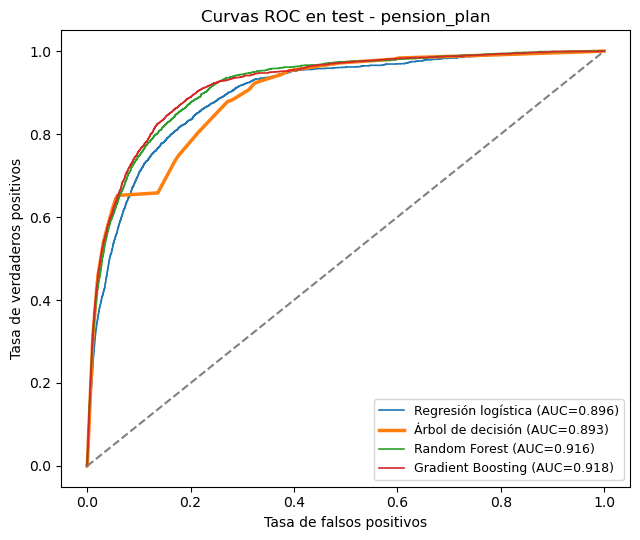

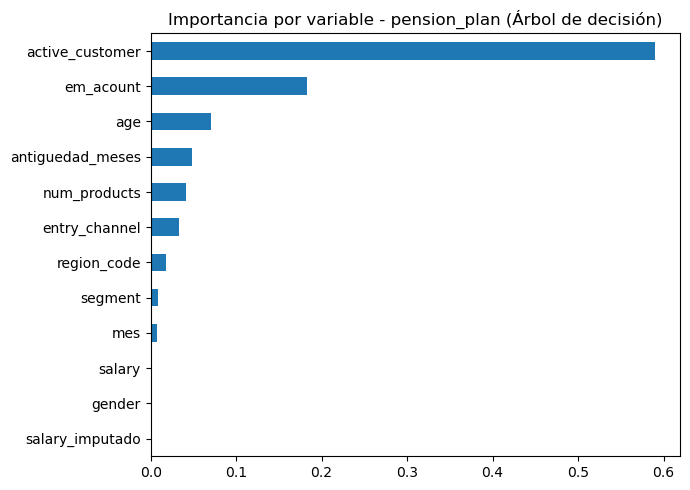

active_customer     0.5898
em_acount           0.1832
age                 0.0707
antiguedad_meses    0.0482
num_products        0.0415
entry_channel       0.0326
region_code         0.0173
segment             0.0090
mes                 0.0069
salary              0.0007
gender              0.0001
salary_imputado     0.0000
dtype: float64


In [14]:
grafico_roc(datos_pension_plan, probas_pension_plan, ganador_pension_plan)
importancia_pension_plan = grafico_importancia(datos_pension_plan, modelos_pension_plan, ganador_pension_plan)
print(importancia_pension_plan.round(4))

**Lectura de la comparación.** *(Completar tras ejecutar con los datos reales.)* Qué modelo gana y por cuánto, si la regresión logística se queda muy lejos (lo que indica que hay relaciones no lineales), si algún modelo sobreajusta (`gap_auc` alto) y qué variables pesan más.

### 4.3 Evaluación del modelo elegido en validación (mayo 2019)

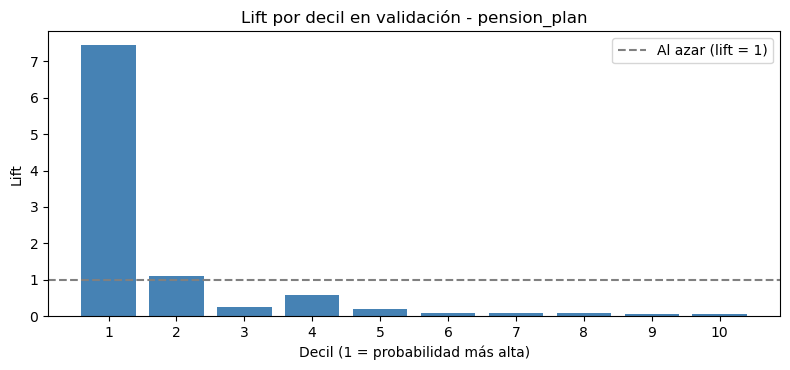

Modelo: Árbol de decisión | AUC validación: 0.904
Top 5 %: 21105 clientes -> 1774 compras de 2791
Conversión top 5 %: 8.41% vs 0.66% al azar -> x12.7

       n_clientes  compras_reales  tasa_conversion   lift  \
decil                                                       
1           42211            2079            0.049  7.449   
2           42210             312            0.007  1.118   
3           42210              73            0.002  0.262   
4           42211             166            0.004  0.595   
5           42210              56            0.001  0.201   
6           42210              26            0.001  0.093   
7           42211              23            0.001  0.082   
8           42210              23            0.001  0.082   
9           42210              15            0.000  0.054   
10          42211              18            0.000  0.064   

       pct_compras_acumulado  
decil                         
1                     74.489  
2                     8

In [15]:
val_pension_plan, lift_pension_plan = evaluar_validacion(datos_pension_plan, modelos_pension_plan[ganador_pension_plan])
lift_pension_plan.to_csv(RUTA + 'lift_pension_plan.csv')

r = val_pension_plan
print(f"Modelo: {ganador_pension_plan} | AUC validación: {r['auc_val']:.3f}")
print(f"Top 5 %: {r['top_n']} clientes -> {r['compras_top5']} compras de {r['compras_total']}")
print(f"Conversión top 5 %: {r['conversion_top5']:.2%} vs {r['conversion_azar']:.2%} al azar -> x{r['lift_top5']:.1f}")
print()
print(lift_pension_plan.round(3))

### 4.4 Scoring para la campaña

In [16]:
scoring_pension_plan = scoring_final(datos_pension_plan, modelos_pension_plan[ganador_pension_plan])
scoring_pension_plan.head(10)

Mes que se predice: 06 | clientes puntuados: 425556
Guardado en ../data/processed/scoring_pension_plan.csv


,pk_cid,probabilidad_pension_plan,decil
0,1120254,0.978945,1
1,1081677,0.972615,1
2,1115366,0.972615,1
3,1227618,0.972615,1
4,1115433,0.972615,1
5,1246790,0.972615,1
6,1115602,0.972615,1
7,1253433,0.972615,1
8,1001363,0.972615,1
9,1368928,0.972615,1


## 5. Modelo de `em_acount`

Cuenta principal de easyMoney y puerta de entrada al resto de productos. Mismo método que `pension_plan`, aplicado a otro producto, para comprobar que generaliza. Aquí `pension_plan_lag1` entra como feature y `em_acount_lag1` solo sirve para definir el universo elegible.

### 5.1 Datos

In [17]:
datos_em_acount = preparar_datos('em_acount', 'pension_plan')

Producto: em_acount | elegibles: 1416834
Test: 2019-04 | Validación: 2019-05
  Train   1134377 filas | positivos:  35371 (3.12%)
  Test     139915 filas | positivos:   2574 (1.84%)
  Val      142542 filas | positivos:   2451 (1.72%)
  Features: 89 columnas


### 5.2 Comparación de los 4 modelos (test)

Es la celda más lenta del notebook: entrena 4 modelos sobre millones de filas.

In [18]:
tabla_em_acount, modelos_em_acount, probas_em_acount = comparar_modelos(datos_em_acount)
ganador_em_acount = tabla_em_acount.loc[0, 'modelo']
tabla_em_acount.to_csv(RUTA + 'comparacion_modelos_em_acount.csv', index=False)

print()
print(tabla_em_acount.round(4).to_string(index=False))
print(f'\nModelo elegido para em_acount: {ganador_em_acount}')

  Regresión logística  entrenado en 6 s
  Árbol de decisión    entrenado en 9 s
  Random Forest        entrenado en 133 s
  Gradient Boosting    entrenado en 28 s

             modelo  auc_train  auc_test  compras_top5_test  prob_distintas_test  segundos_entreno  gap_auc
  Gradient Boosting     0.9067    0.8701               1344                55966              27.8   0.0367
      Random Forest     0.9169    0.8704               1340               107317             132.9   0.0465
  Árbol de decisión     0.8848    0.8671               1287                   40               9.2   0.0177
Regresión logística     0.8355    0.8169                661               119576               6.1   0.0186

Modelo elegido para em_acount: Gradient Boosting


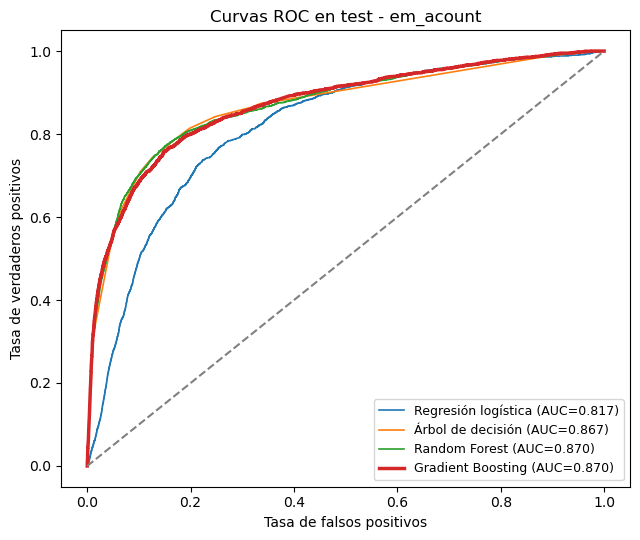

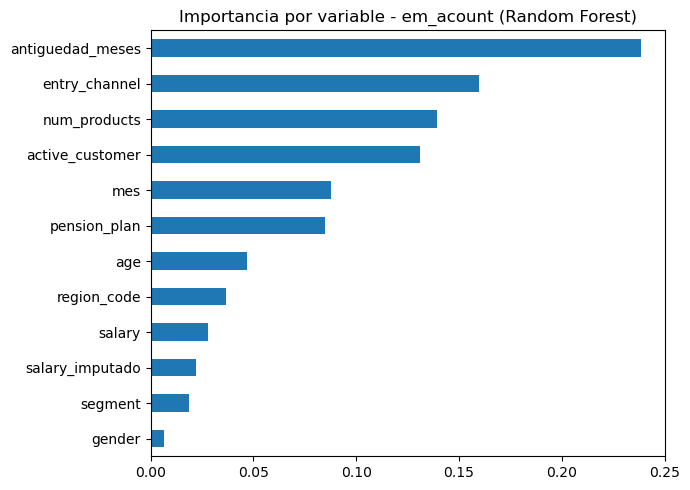

antiguedad_meses    0.2385
entry_channel       0.1596
num_products        0.1393
active_customer     0.1309
mes                 0.0877
pension_plan        0.0850
age                 0.0469
region_code         0.0366
salary              0.0281
salary_imputado     0.0220
segment             0.0188
gender              0.0066
dtype: float64


In [19]:
grafico_roc(datos_em_acount, probas_em_acount, ganador_em_acount)
importancia_em_acount = grafico_importancia(datos_em_acount, modelos_em_acount, ganador_em_acount)
print(importancia_em_acount.round(4))

**Lectura de la comparación.** *(Completar tras ejecutar con los datos reales.)* Qué modelo gana y por cuánto, si la regresión logística se queda muy lejos (lo que indica que hay relaciones no lineales), si algún modelo sobreajusta (`gap_auc` alto) y qué variables pesan más.

### 5.3 Evaluación del modelo elegido en validación (mayo 2019)

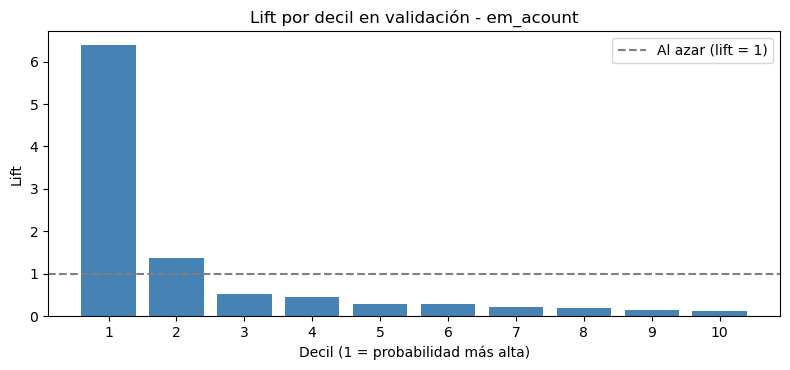

Modelo: Gradient Boosting | AUC validación: 0.859
Top 5 %: 7127 clientes -> 1244 compras de 2451
Conversión top 5 %: 17.45% vs 1.72% al azar -> x10.2

       n_clientes  compras_reales  tasa_conversion   lift  \
decil                                                       
1           14255            1567            0.110  6.393   
2           14254             334            0.023  1.363   
3           14254             131            0.009  0.534   
4           14254             109            0.008  0.445   
5           14254              68            0.005  0.277   
6           14254              72            0.005  0.294   
7           14254              55            0.004  0.224   
8           14254              50            0.004  0.204   
9           14254              36            0.003  0.147   
10          14255              29            0.002  0.118   

       pct_compras_acumulado  
decil                         
1                     63.933  
2                     7

In [20]:
val_em_acount, lift_em_acount = evaluar_validacion(datos_em_acount, modelos_em_acount[ganador_em_acount])
lift_em_acount.to_csv(RUTA + 'lift_em_acount.csv')

r = val_em_acount
print(f"Modelo: {ganador_em_acount} | AUC validación: {r['auc_val']:.3f}")
print(f"Top 5 %: {r['top_n']} clientes -> {r['compras_top5']} compras de {r['compras_total']}")
print(f"Conversión top 5 %: {r['conversion_top5']:.2%} vs {r['conversion_azar']:.2%} al azar -> x{r['lift_top5']:.1f}")
print()
print(lift_em_acount.round(3))

### 5.4 Scoring para la campaña

In [21]:
scoring_em_acount = scoring_final(datos_em_acount, modelos_em_acount[ganador_em_acount])
scoring_em_acount.head(10)

Mes que se predice: 06 | clientes puntuados: 146575
Guardado en ../data/processed/scoring_em_acount.csv


,pk_cid,probabilidad_em_acount,decil
0,1436036,0.976068,1
1,1431333,0.973566,1
2,1427989,0.973168,1
3,1283077,0.970291,1
4,1430352,0.968088,1
5,1462330,0.968024,1
6,1188488,0.967585,1
7,1256778,0.967157,1
8,1417642,0.966925,1
9,1039574,0.966646,1


## 6. Resumen de los dos productos

Generado desde el código, para que nunca quede desactualizado.

In [22]:
filas = []
for prod in PRODUCTOS_MODELO:
    tabla, ganador, r = globals()[f'tabla_{prod}'], globals()[f'ganador_{prod}'], globals()[f'val_{prod}']
    lift = globals()[f'lift_{prod}']
    filas.append({'producto': prod, 'modelo_elegido': ganador,
                  'auc_test': tabla.loc[0, 'auc_test'], 'auc_validacion': r['auc_val'],
                  'conversion_top5_val': f"{r['conversion_top5']:.2%}",
                  'conversion_azar_val': f"{r['conversion_azar']:.2%}",
                  'lift_top5_val': round(r['lift_top5'], 1),
                  'pct_compras_deciles_1a3': round(lift.loc[3, 'pct_compras_acumulado'], 1),
                  'clientes_puntuados': len(globals()[f'scoring_{prod}'])})
resumen = pd.DataFrame(filas).set_index('producto').T
resumen

producto,pension_plan,em_acount
modelo_elegido,Árbol de decisión,Gradient Boosting
auc_test,0.892884,0.870053
auc_validacion,0.904336,0.858726
conversion_top5_val,8.41%,17.45%
conversion_azar_val,0.66%,1.72%
lift_top5_val,12.7,10.2
pct_compras_deciles_1a3,88.3,82.9
clientes_puntuados,425556,146575


**Salidas para la Tarea 4** (en `../data/processed/`):
- `scoring_pension_plan.csv` y `scoring_em_acount.csv`: probabilidad y decil de cada cliente elegible para junio.
- `validacion_pension_plan.csv` y `validacion_em_acount.csv`: probabilidad y compra real de cada cliente en validación (mayo). Con esto la Tarea 4 mide la conversión real de cada estrategia.

**Salidas para comprobación** (en `../data/processed/`):
- `lift_pension_plan.csv` y `lift_em_acount.csv`: conversión real por decil en validación.
- `comparacion_modelos_pension_plan.csv` y `comparacion_modelos_em_acount.csv`: tabla de comparación de los 4 modelos.